### 工作進度  
* 【置頂】**筆記內容架構**與**量化技術分析系統**相關資訊請參閱[260531筆記.ipynb](https://github.com/yilintung/StockInvestmentNotebook/blob/main/260531%E7%AD%86%E8%A8%98.ipynb)之「工作進度」。  
* 盤前資訊  
  先講**重點**，如果資金較多，[正二](https://tw.stock.yahoo.com/quote/00631L.TW)你今天就可以開始買了，但不是一次買完，一樣要留點子彈，後面跌更多要越敢買。如果你資金少，那等止跌跟轉折更明確再進場。  
  其他等一下看[解盤](https://www.facebook.com/kevinyang20180801/posts/pfbid037VmLdXGCeSc7w9EpXhXwxLscH9N3M5gj9U17T2QXgzPq9xfUPN6kSB95dupX91dNl?rdid=2IwtiQrqvEKaYSxw#)。  
* 盤前資訊  
  不要說一般人，即使我使用技術分析這麼久，真的也看到做頭訊號，還是很難想像，日經指數最後真的做頭了。  
  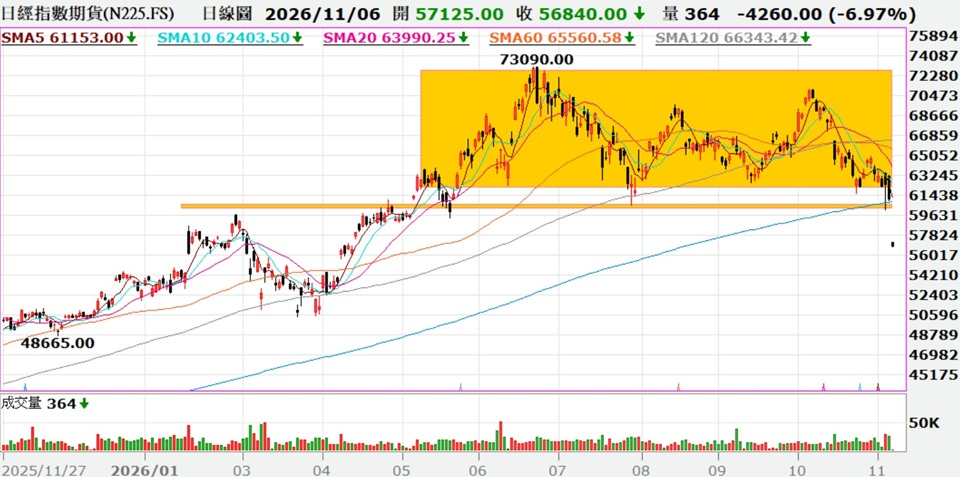  
    
  費半跟日本，一直是本波修正的對照觀察：  
  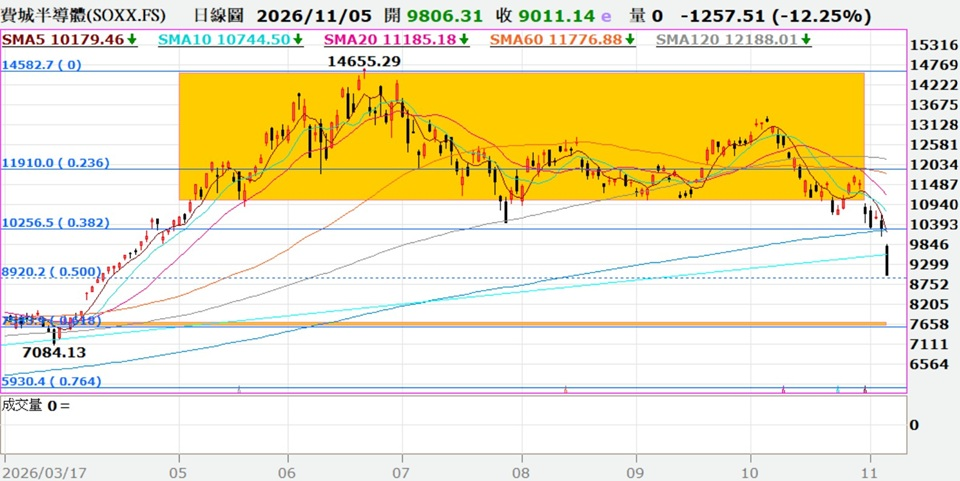  
  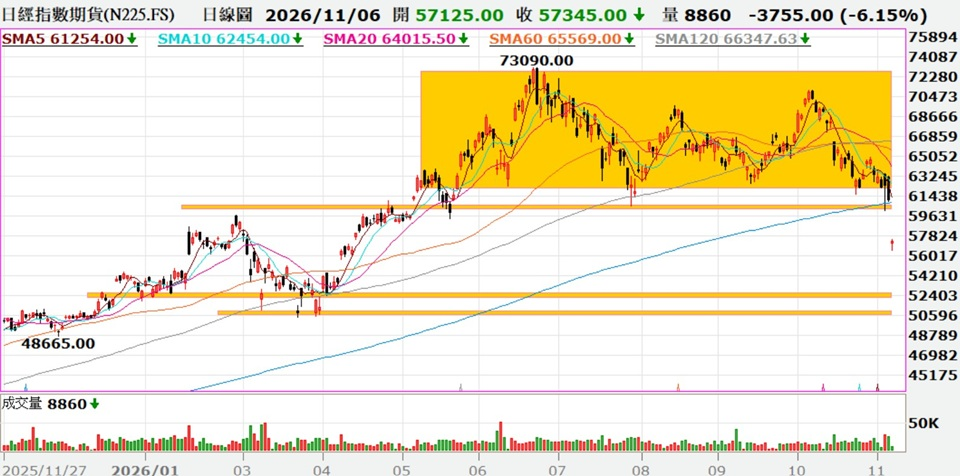  
    
  同學問我，費半跟日本，真的會到跌幅滿足嗎？  
  坦白說這次還真沒把握，現在劇本有兩套，但很極端。  
  一個是今天是恐慌性假跌破，3-5天內站回頸縣，那這次危機跟修正就算結束。另一個劇本就是依照頭部理論，直接到跌幅滿足。  
  而這兩套劇本機率我目前認為是各半，但唯一共同點，都會在幾天內見真章。  
  因為這會直接連動台股，所以因應這種極端劇本，我才會擬定早上說的正二買進的方式跟策略。  

* 引入模組與定義公用函式  

In [ ]:
import numpy as np
import mysys
import markdown
from IPython.core.display import HTML

In [ ]:
def stock_analysis( analysis, stock_id, buttom_pattern = False) :
    results,images = analysis.analysis(stock_id)
    if results is not None :
        if buttom_pattern is True and '底部型態' in images :
            print('底型反轉交易策略：')
            display(images['底部型態'])
        print('解盤內容：')
        if '整體評價' in images and images['整體評價'] is not None  :
            display(images['整體評價'])
        result_md   = results.to_markdown(tablefmt="grid")
        result_html = markdown.markdown(result_md, extensions=['markdown_grid_tables:GridTableExtension'])
        display(HTML(result_html))

* 更新量化技術分析資料庫  

In [ ]:
mysys.UpdateStockDatabase()

* 建立「解盤」物件    

In [ ]:
analysis = mysys.StockAnalysis()

### 大盤解盤  

* 加權指數  

> **開盤**：加權指數跌破前低和年線。  
> 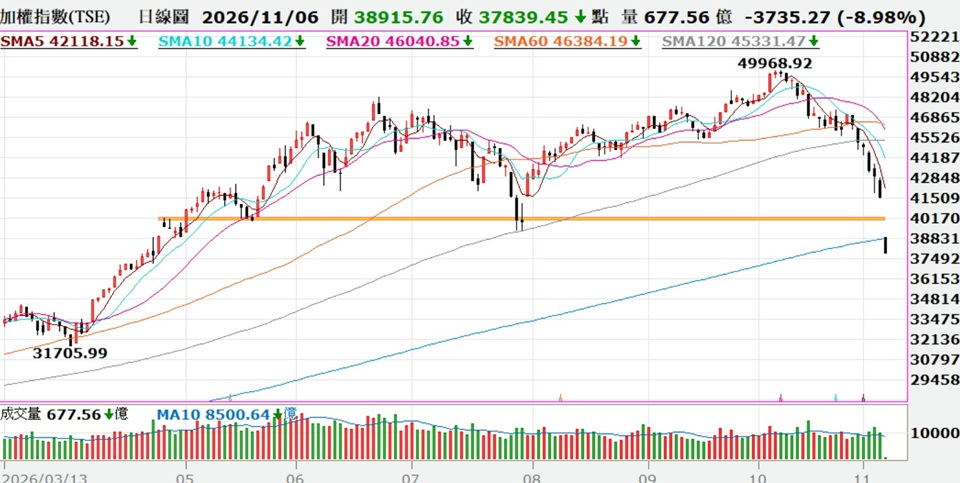  
> **盤中**：總算出現一點曙光了。  
> 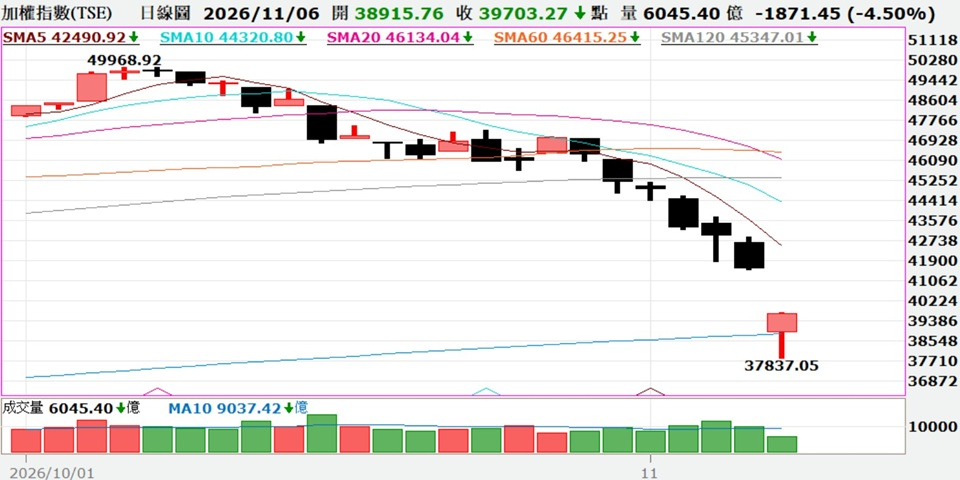  

> **盤後**：量化技術分析  

In [ ]:
# 盤後：加權指數解盤
stock_analysis(analysis,'TAIEX')

* 櫃買指數  

> **開盤**：櫃買指數也是開低，頭部型態更加明確。  
> 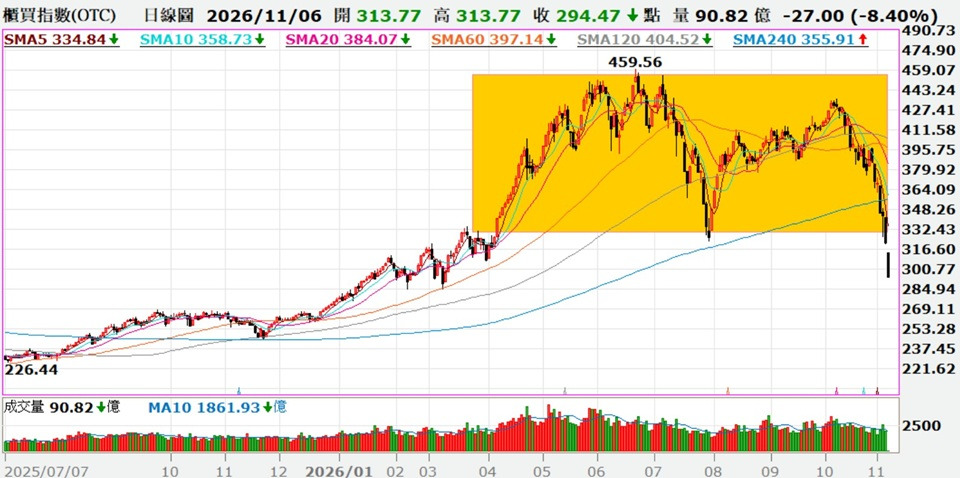  
> **盤中**：TODO。  
> TODO  

> **盤後**：量化技術分析  

In [ ]:
# 盤後：櫃買指數解盤
stock_analysis(analysis,'TPEx')

### 個股篩選  

* 選股程序    

In [ ]:
results = analysis.screener()

In [ ]:
for stock_info in results :
    print('股票代碼 ＝ {} ， 股票名稱 ＝ {} '.format(stock_info[0],stock_info[1]))

* 篩選結果  
  - 彰銀(2801)：多頭回檔  
    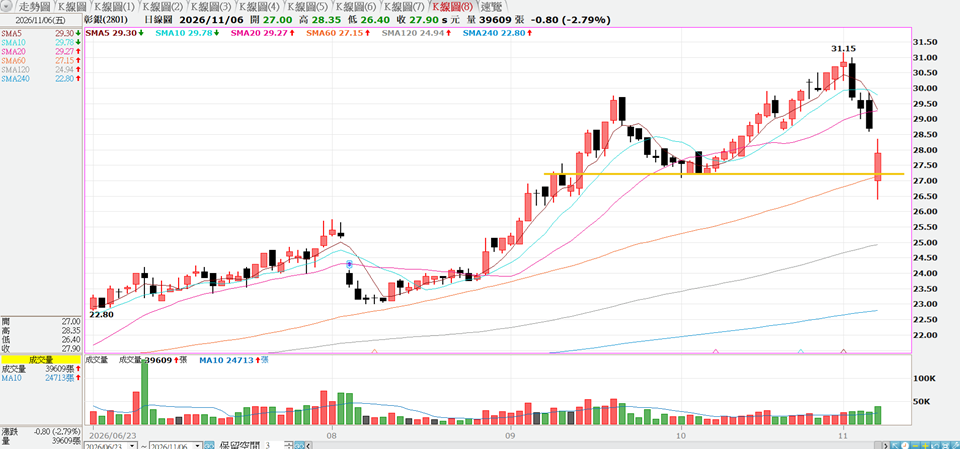  
  - 台泥(1101)：多頭回檔  
    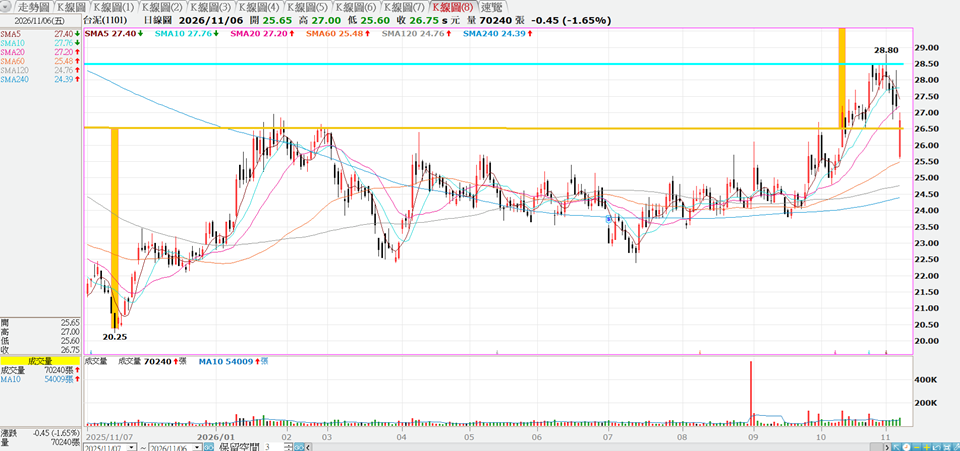  
  - 新建(2516)：多頭回檔  
    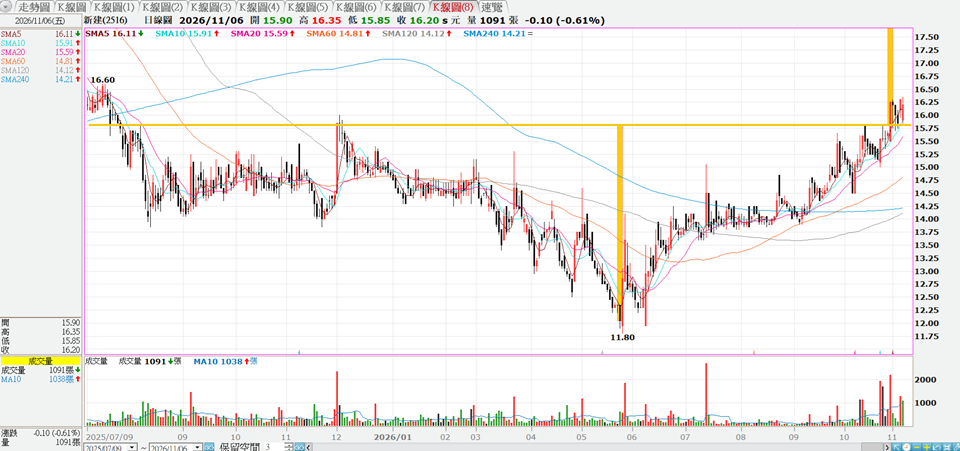  
  - 上海商銀(5876)：多頭回檔  
    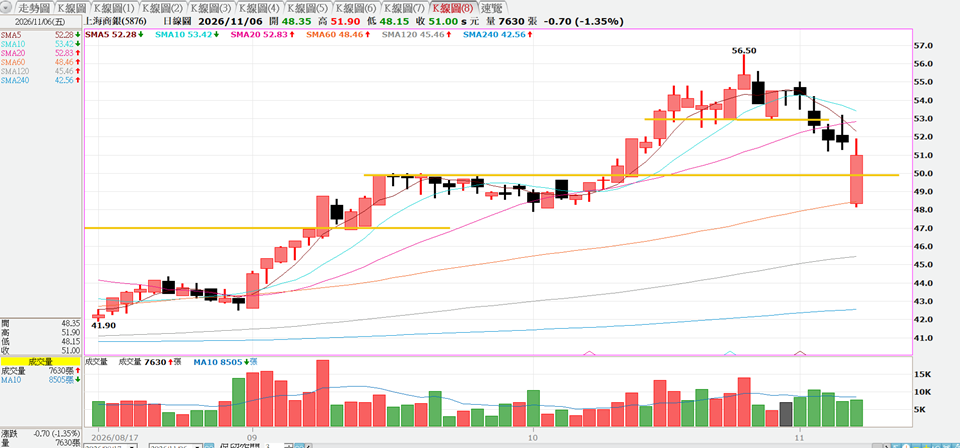  

* 觀察股列表  
  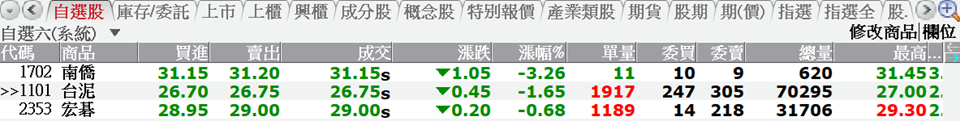  

### 個股解盤  

* 台泥(1101)  
  看法：短線轉空，中期回測頸線支撐。  

> **盤後**：量化技術分析  

In [ ]:
stock_analysis(analysis,'1101')

> **盤後**：底部反轉交易策略分析  

In [ ]:
def line_drawing_callback( range_prices) :
    # 設定頸線
    neckline_start_date  = '2025-06-05'
    neckline_end_date   = range_prices.iloc[-1].name.strftime("%Y-%m-%d")
    neckline_price      = range_prices.loc['2026-01-29']['Close']

    # 設定底部日期與價格
    bottom_date           = '2025-11-19'
    bottom_price          = range_prices.loc['2025-11-19']['Close']

    # 估算目標價
    target_price = (neckline_price - bottom_price) + neckline_price

    print('估算目標價為{:.2f}元'.format(target_price))

    # 設定突破日期
    breakout_date = '2026-10-12'
    
    seq_of_seq_of_points=[
        [(neckline_start_date,neckline_price),(neckline_end_date,neckline_price)],
        [(bottom_date,bottom_price),(bottom_date,neckline_price)],
        [(breakout_date,neckline_price),(breakout_date,target_price)]
    ]

    linewidths=[2.0,15.0,15.0]
    
    colors=['xkcd:orange yellow','xkcd:orange yellow','xkcd:orange yellow']
    
    return seq_of_seq_of_points,linewidths,colors

In [ ]:
image = mysys.DrawOnKlineChart('1101','2025-03-20','2026-11-06',line_drawing_callback)
display(image)

籌碼面：  
法人大買(+17516)：外資大買(+17591)、投信中立(0)、自營小賣(-75)。  
主力小買(+6525)。  
分公司買賣家數差分散(-40)。  
融資○○( )、融券○○( )。  